# Instead of testing difference between OC and NOC composites at each grid point, test aggregate differences 

This is more ideal for variables such as CAPE that are 0 bounded, and PV advection which has sharp gradients and is very noisy

In [1]:
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from scipy.stats import permutation_test

In [2]:
COMP_DIR = "/data1/lepique/composites_matched_month1to1"
PVU_DAY = 1e6 * 86400
OC_COLOR, NOC_COLOR = "#C0392B", "#2C6FAD"

thresholds=[2, 5, -2, -5]
sweep=np.arange(0, 15.01, 0.5)


In [3]:
# Nodefilecompose default (xy) grid with --dx 1.0: each cell is ~1 degree by 1 degree of 
# great circle distance. 
KM_PER_DEG = 2 * np.pi * 6371.0 / 360.0
CELL_AREA = KM_PER_DEG**2 / 1e4      # 100km^2 per cell (same as TN2019)

In [22]:
# file tag -> variable inside the file, unit scaling, box half widths, thresholds
FIELDS = {
    "cape": dict(var="cape", scale=1.0, units="J kg$^{-1}$", label="CAPE",
                 max_half=10, area_half=10,
                 thresholds=[250, 500], sweep=np.arange(0, 1501, 50)),
    "pvadv_chi_l": dict(var="pvadv_chi_l", scale=PVU_DAY, units="PVU day$^{-1}$",
                        label="300–200 hPa $-\\mathbf{V}_\\chi\\cdot\\nabla PV$",
                        max_half=10, area_half=10,
                        # thresholds=[1, 2, 5], 
                        thresholds=[-2, -5],
                        sweep=np.arange(-15.0, 2, 1)),
    # "pvadv_chi250": dict(var="pvadv_chi(1)", scale=PVU_DAY, units="PVU day$^{-1}$",
    #                      label="250 hPa $-\\mathbf{V}_\\chi\\cdot\\nabla PV$",
    #                      max_half=10, area_half=15,
    #                      thresholds=[1, 2, 5], sweep=np.arange(0, 15.01, 0.5)),
}

In [5]:
def load_snaps(pop, tag, comp_dir = COMP_DIR):
    """per cyclone snapshot stack (n, ny, nx) in plotting units, plus x, y."""
    f = FIELDS[tag]
    ds = xr.open_dataset(f"{comp_dir}/{pop}_min_msl_{tag}.nc", decode_times=False)
    snaps = ds[f"snap_{f['var']}"].values.astype(np.float64) * f["scale"]
    return snaps, ds["x"].values, ds["y"].values

In [6]:
SNAPS = {}
for tag in FIELDS:
    for pop in ("oc", "noc"):
        SNAPS[tag, pop], X, Y = load_snaps(pop, tag)
    print(f"{tag:14s} OC {SNAPS[tag, 'oc'].shape}  NOC {SNAPS[tag, 'noc'].shape}")

cape           OC (114, 80, 80)  NOC (114, 80, 80)
pvadv_chi_l    OC (114, 80, 80)  NOC (114, 80, 80)


In [7]:
def box_mask(x, y, half):
    """Square box |x|, |y| <- half (degrees from center). Cell centers sit at +-0.5, +-1.5,...
    so half = 10 > 20x20 cells, half=15 > 30x30."""
    return (np.abs(y)[:, None] <= half) & (np.abs(x)[None, :] <= half)

def in_box(snaps, mask, require_full=True):
    """(n, n_cells) values inside the box, plus a keep-mask over cyclones.
    CAPE comes from the regional era5_TE_composite download, so cyclones near
    ~290-295E have the east side of the box past the domain edge (NaN). With
    require_full=True those cyclones are dropped rather than given a truncated
    max/area."""
    sub = snaps[:, mask]
    keep = ~np.isnan(sub).any(axis=1) if require_full else np.ones(len(sub), bool)
    return sub, keep

def cyc_max(snaps, mask, require_full=False):
    sub, keep = in_box(snaps, mask, require_full)
    return np.nanmax(sub[keep], axis=1)

def cyc_min(snaps, mask, require_full=False):
    sub, keep = in_box(snaps, mask, require_full)
    return np.nanmin(sub[keep], axis=1)

def cyc_area_above(snaps, mask, thr, require_full=False):
    sub, keep = in_box(snaps, mask, require_full)
    return (sub[keep] > thr).sum(axis=1) * CELL_AREA      # (100 km)^2

def cyc_area_below(snaps, mask, thr, require_full=False):
    sub, keep = in_box(snaps, mask, require_full)
    return (sub[keep] < thr).sum(axis=1) * CELL_AREA 

In [8]:
def _mean_diff(a, b, axis=-1):
    return np.mean(a, axis=axis) - np.mean(b, axis=axis)

def _median_diff(a, b, axis=-1):
    return np.median(a, axis=axis) - np.median(b, axis=axis)

def two_sample_test(oc, noc, n_resamples=10000, seed=1):
    """Permutation test (as in Tochimoto et al. 2019)
    on per-cyclone scalars: difference of means, plus difference of medians
    (robust to the skewed, zero-inflated area values)."""
    out = {"n_oc": len(oc), "n_noc": len(noc)}
    for name, g in (("oc", oc), ("noc", noc)):
        out[f"{name}_mean"] = np.mean(g)
        for q in (10, 25, 50, 75, 90):
            out[f"{name}_p{q}"] = np.percentile(g, q)
    for name, stat in (("mean", _mean_diff), ("median", _median_diff)):
        res = permutation_test((oc, noc), stat, permutation_type="independent",
                               vectorized=True, n_resamples=n_resamples,
                               alternative="two-sided", random_state=seed)
        out[f"d_{name}"], out[f"p_{name}"] = res.statistic, res.pvalue
    return out


In [9]:
def plot_box(ax, oc, noc, ylabel, title, st, seed=0):
    """Tochimoto et al. (2019) Figs. 7/8 style: box = 25-75th pct, whiskers =
    10-90th pct, line = median. Per-cyclone values overlaid as jittered dots."""
    bp = ax.boxplot([oc, noc], whis=(10, 90), showfliers=False, widths=0.5,
                    patch_artist=True, medianprops=dict(color="k", lw=1.8))
    rng = np.random.default_rng(seed)
    for i, (g, c, box) in enumerate(zip((oc, noc), (OC_COLOR, NOC_COLOR), bp["boxes"]), start=1):
        box.set(facecolor=c, alpha=0.35, edgecolor=c)
        # ax.scatter(i + rng.uniform(-0.13, 0.13, len(g)), g, s=7, color=c,
        #            alpha=0.45, lw=0, zorder=3)
    ax.set_xticks([1, 2], [f"OC (n={len(oc)})", f"NOC (n={len(noc)})"])
    ax.set_ylabel(ylabel)
    ax.set_title(title, fontsize=10)
    ax.grid(axis="y", alpha=0.3)
    ax.text(0.98, 0.98,
            f"Δmedian = {st['d_median']:.3g}  (p = {st['p_median']:.3f})\n"
            f"Δmean = {st['d_mean']:.3g}  (p = {st['p_mean']:.3f})",
            transform=ax.transAxes, ha="right", va="top", fontsize=8,
            bbox=dict(fc="white", ec="0.7", alpha=0.85))

In [10]:
rows = []

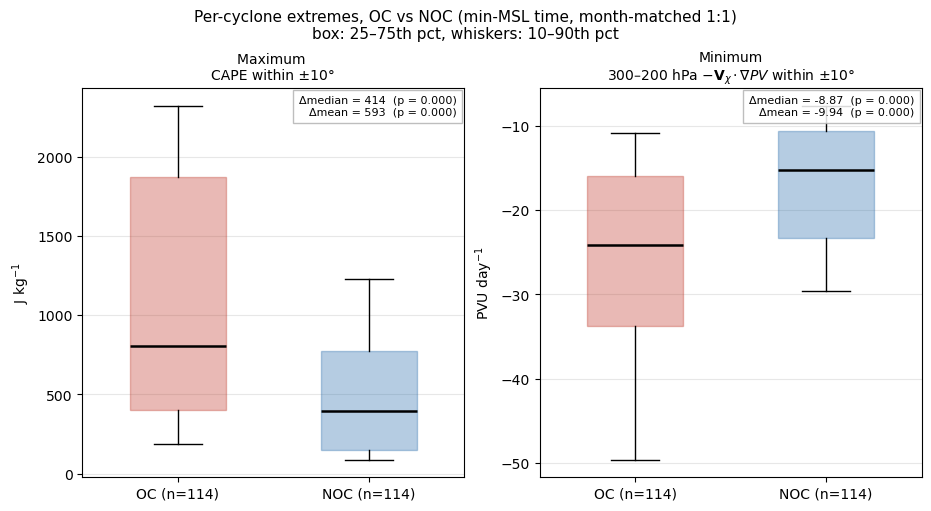

In [11]:
# per-cyclone extremes within the box (cf. Tochimoto Fig. 8) ---
PANELS_A = [("cape", "max"),
            #("pvadv_chi_l", "max"), 
            ("pvadv_chi_l", "min"),
            #("pvadv_chi250", "max"), 
            #("pvadv_chi250", "min")
            ]

fig, axes = plt.subplots(1, len(PANELS_A), figsize=(4.6 * len(PANELS_A), 5),
                         constrained_layout=True)
for ax, (tag, kind) in zip(axes, PANELS_A):
    f = FIELDS[tag]
    m = box_mask(X, Y, f["max_half"])
    fn = cyc_max if kind == "max" else cyc_min
    oc, noc = (fn(SNAPS[tag, p], m) for p in ("oc", "noc"))
    st = two_sample_test(oc, noc)
    rows.append({"field": tag, "metric": f"{kind}, ±{f['max_half']}°",
                 "threshold": np.nan, **st})
    word = "Maximum " if kind == "max" else "Minimum"
    plot_box(ax, oc, noc, f["units"],
             f"{word}\n{f['label']} within ±{f['max_half']}°", st)
fig.suptitle("Per-cyclone extremes, OC vs NOC (min-MSL time, month-matched 1:1)\n"
             "box: 25–75th pct, whiskers: 10–90th pct", fontsize=11)
plt.show()

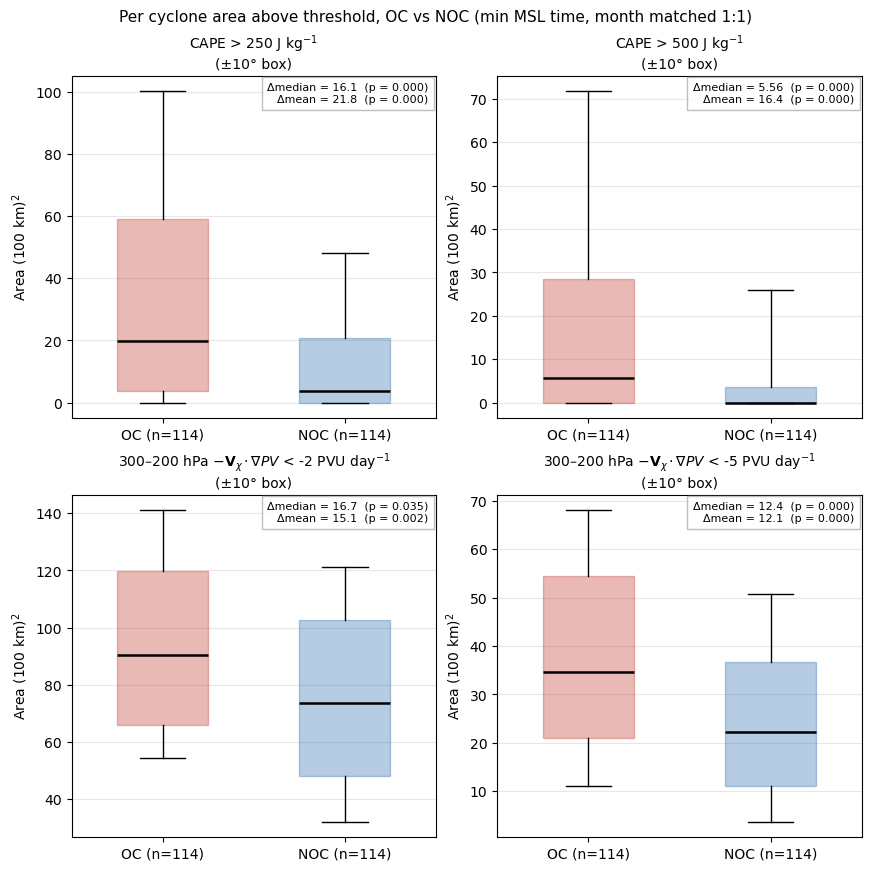

In [12]:
ncol = max(len(f["thresholds"]) for f in FIELDS.values())
fig, axes = plt.subplots(len(FIELDS), ncol, figsize = (4.3 * ncol, 4.3 * len(FIELDS)),
                         constrained_layout=True, squeeze=False)
for r, (tag, f) in enumerate(FIELDS.items()):
    m = box_mask(X, Y, f["area_half"])
    for c, thr in enumerate(f["thresholds"]):
        area_fn = cyc_area_above if thr >= 0 else cyc_area_below
        rel = ">" if thr >= 0 else "<"
        oc, noc = (area_fn(SNAPS[tag, p], m, thr) for p in ("oc", "noc"))
        st = two_sample_test(oc, noc)
        rows.append({"field": tag, "metric": f"area {rel} thr, ±{f['area_half']}°",
                     "threshold": thr, **st})
        plot_box(axes[r, c], oc, noc, "Area (100 km)$^2$",
                 f"{f['label']} {rel} {thr} {f['units']}\n(±{f['area_half']}° box)", st)


        # oc, noc = (cyc_area_above(SNAPS[tag, p], m, thr) for p in ("oc", "noc")) 
        # st = two_sample_test(oc, noc)
        # rows.append({"field": tag, "metric": f"area > thr, ±{f['area_half']}°",
        #              "threshold": thr, **st})
        # plot_box(axes[r,c], oc, noc, "Area (100 km)$^2$)",
        #         f"{f['label']} > {thr} {f['units']}\n(±{f['area_half']}° box)", st)
        
    for c in range(len(f["thresholds"]), ncol):
        axes[r, c].set_visible(False)
fig.suptitle("Per cyclone area above threshold, OC vs NOC (min MSL time, month matched 1:1)",
             fontsize=11)
plt.show()

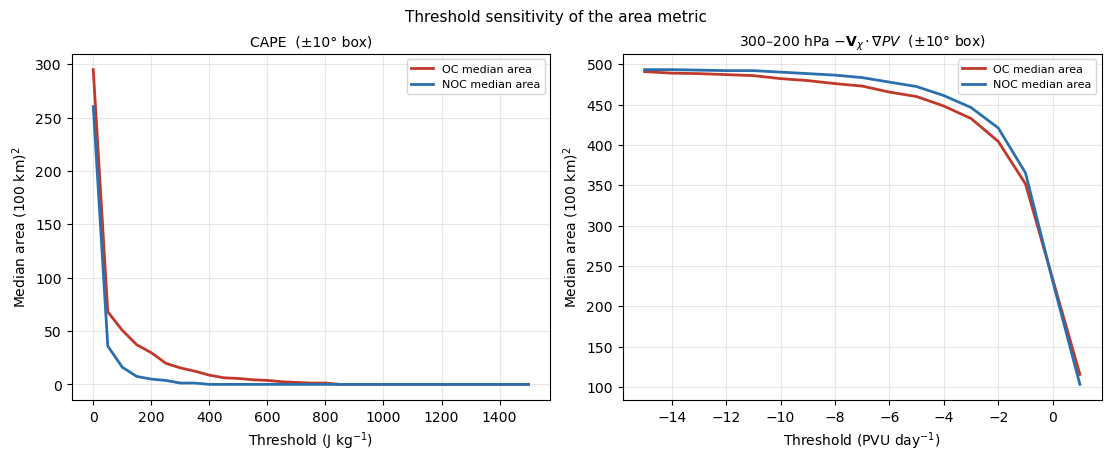

In [23]:
fig, axes = plt.subplots(1, len(FIELDS), figsize=(5.5 * len(FIELDS), 4.5), constrained_layout=True)
for ax, (tag, f) in zip(axes, FIELDS.items()):
    m = box_mask(X, Y, f["area_half"])
    med_oc, med_noc, p_med, p_mean = [], [], [], []
    for thr in f["sweep"]:
        oc, noc = (cyc_area_above(SNAPS[tag, p], m, thr) for p in ("oc", "noc"))
        st = two_sample_test(oc, noc, n_resamples=5000)
        med_oc.append(st["oc_p50"]); med_noc.append(st["noc_p50"])
        p_med.append(st["p_median"]); p_mean.append(st["p_mean"])
    ax.plot(f["sweep"], med_oc, color=OC_COLOR, lw=2, label="OC median area")
    ax.plot(f["sweep"], med_noc, color=NOC_COLOR, lw=2, label="NOC median area")
    ax.set_xlabel(f"Threshold ({f['units']})")
    ax.set_ylabel("Median area (100 km)$^2$")
    ax.set_title(f"{f['label']}  (±{f['area_half']}° box)", fontsize=10)
    ax.grid(alpha=0.3)
    #ax2 = ax.twinx()
    #ax2.semilogy(f["sweep"], p_mean, "k-", lw=1, label="p (Δmean)")
    #ax2.semilogy(f["sweep"], p_med, "k--", lw=1, label="p (Δmedian)")
    #ax2.axhline(0.05, color="gray", ls=":", lw=1)
    #ax2.set_ylim(1e-4, 1.05)
    #ax2.set_ylabel("permutation p")
    h1, l1 = ax.get_legend_handles_labels()
    #l2 = ax2.get_legend_handles_labels()
    ax.legend(h1, l1, fontsize=8, loc="upper right")
fig.suptitle("Threshold sensitivity of the area metric",
             fontsize=11)
plt.show()